# 20 October: editable optics demonstrations

Companion to `study_notes_20_oct.pdf`. The scalar pupil model is deliberately explicit: clear circular aperture, paraxial propagation, vacuum image space, and negative Fourier kernel. Edit the parameter cell and run it and all subsequent cells. Coefficients are in vacuum wavelengths; multiply by `wavelength_nm` for nanometres. The film optical constants are illustrative, not measured material values.

In [1]:
from pathlib import Path
import sys, numpy as np, matplotlib.pyplot as plt
from optics_calculations import (zernike, gradient_function, pupil_grid, psf_from_waves, stack_reflection, ATLAS)
print('Python:', sys.executable)

Python: C:\Users\fxl04\Desktop\Prof. Wong Grp Papers\Ray Optics\.venv\Scripts\python.exe


## Editable parameters
Choose an allowed `(n,m)` with `n ≥ |m|` and `n−|m|` even. Positive `m` is cosine; negative is sine. `coefficient_waves` is the RMS coefficient for a nonpiston normalized mode. Added defocus is a separate coefficient of `Z₂⁰`.

In [2]:
wavelength_nm = 13.5
mode_n, mode_m = 3, 1
coefficient_waves = 0.15
added_defocus_waves = 0.0
pupil_samples = 256
fft_padding = 8
image_half_range = 3.0
# Illustrative planar stack, physical nanometres; indices = ambient, films, substrate.
indices = [1+0j, 0.95+0.02j, 0.99+0.005j, 1.2+0j]
film_thickness_nm = [3.0, 4.0]
incidence_deg = 6.0
polarization = 's'

## Pupil → ray intercepts → diffraction intensity
The image axes are `s = NA*x/λ₀`; geometric intercepts obey `s = ∇(W/λ₀)`. Diffraction is normalized to the ideal peak for the same pupil, not to its own maximum.

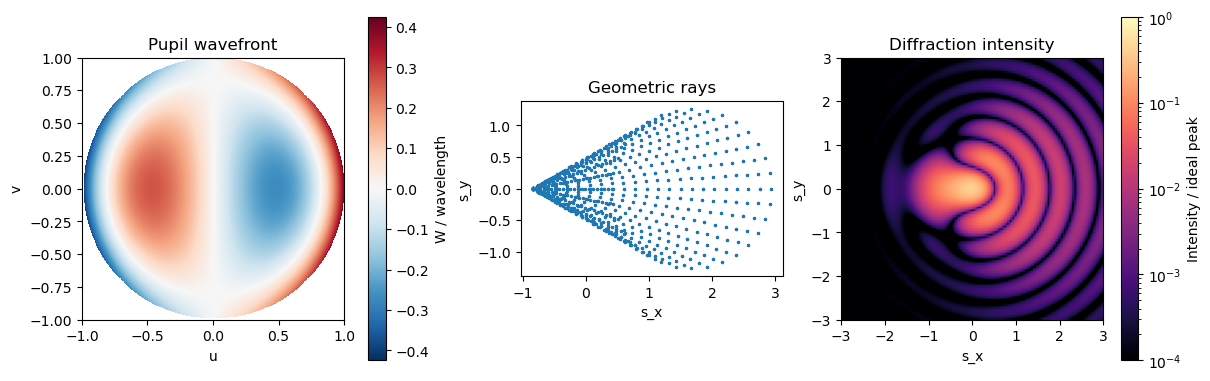

Sampled RMS [waves]: 0.14982326644398225
RMS [nm]: 2.0226140969937605
Peak / ideal peak: 0.4018054381957472


In [3]:
u,v,mask,du = pupil_grid(pupil_samples)
waves = coefficient_waves*zernike(mode_n,mode_m,u,v) + added_defocus_waves*zernike(2,0,u,v)
s,I = psf_from_waves(waves,mask,du,fft_padding)
cut = abs(s)<=image_half_range
from matplotlib.colors import LogNorm
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
lim=max(.02,abs(waves[mask]).max())
im=ax[0].imshow(np.where(mask,waves,np.nan),origin='lower',extent=(-1,1,-1,1),cmap='RdBu_r',vmin=-lim,vmax=lim)
fig.colorbar(im,ax=ax[0],label='W / wavelength')
ax[0].set(xlabel='u',ylabel='v',title='Pupil wavefront')
r=np.sqrt(np.linspace(.005,.99,22)); th=np.linspace(0,2*np.pi,64,endpoint=False)
ru=(r[:,None]*np.cos(th)).ravel(); rv=(r[:,None]*np.sin(th)).ravel()
gx,gy=gradient_function(mode_n,mode_m)(ru,rv); fx,fy=gradient_function(2,0)(ru,rv)
ax[1].scatter(coefficient_waves*np.broadcast_to(gx,ru.shape)+added_defocus_waves*fx,coefficient_waves*np.broadcast_to(gy,rv.shape)+added_defocus_waves*fy,s=2)
ax[1].set(xlabel='s_x',ylabel='s_y',title='Geometric rays',aspect='equal')
im=ax[2].imshow(I[np.ix_(cut,cut)],origin='lower',extent=(s[cut][0],s[cut][-1],s[cut][0],s[cut][-1]),cmap='magma',norm=LogNorm(1e-4,1))
fig.colorbar(im,ax=ax[2],label='Intensity / ideal peak')
ax[2].set(xlabel='s_x',ylabel='s_y',title='Diffraction intensity')
plt.show()
print('Sampled RMS [waves]:',waves[mask].std())
print('RMS [nm]:',waves[mask].std()*wavelength_nm)
print('Peak / ideal peak:',I.max())

## The requested 12-panel atlas
All maps share one numerical, dimensionless scale. The coefficient sets the physical OPD scale. The notebook regenerates the same mode order as the PDF.

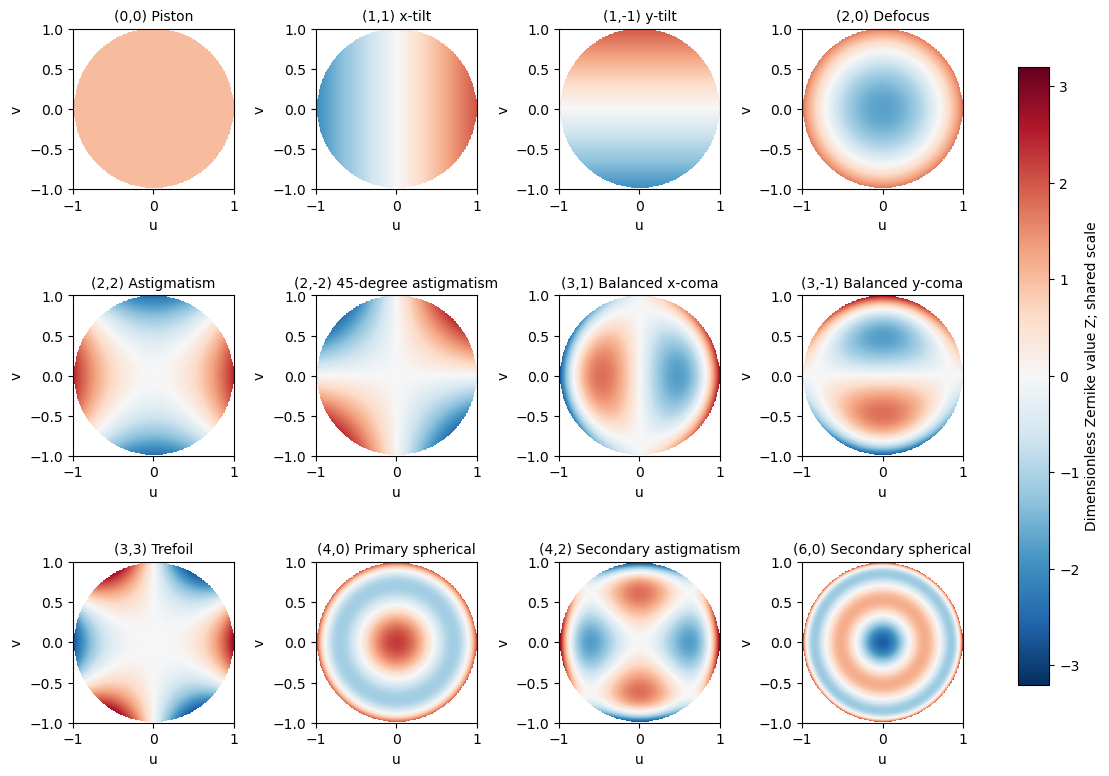

In [4]:
fig,axes=plt.subplots(3,4,figsize=(11,8),layout='constrained')
for ax,(n,m,name) in zip(axes.flat,ATLAS):
    im=ax.imshow(np.where(mask,zernike(n,m,u,v),np.nan),origin='lower',extent=(-1,1,-1,1),cmap='RdBu_r',vmin=-3.2,vmax=3.2)
    ax.set_title(f'({n},{m}) {name}',fontsize=10)
    ax.set(xlabel='u',ylabel='v')
fig.colorbar(im,ax=axes,shrink=.8,label='Dimensionless Zernike value Z; shared scale')
plt.show()

## A multilayer thickness sweep
Bottom-up effective-reflection recursion; `s` and `p` use different tangential admittances. Only the first finite layer is varied. The phase is unwrapped over this sweep and becomes ill-conditioned near reflection zeros.

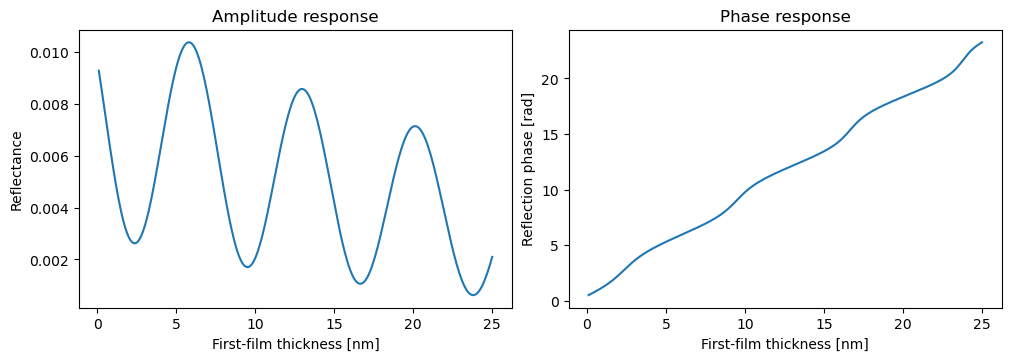

In [5]:
thickness_sweep_nm=np.linspace(0.1,25,300)
rs=[]
for thickness in thickness_sweep_nm:
    d=list(film_thickness_nm); d[0]=float(thickness)
    rs.append(stack_reflection(indices,d,wavelength_nm,np.deg2rad(incidence_deg),polarization))
rs=np.array(rs)
fig,ax=plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
ax[0].plot(thickness_sweep_nm,abs(rs)**2); ax[0].set(xlabel='First-film thickness [nm]',ylabel='Reflectance',title='Amplitude response')
ax[1].plot(thickness_sweep_nm,np.unwrap(np.angle(rs))); ax[1].set(xlabel='First-film thickness [nm]',ylabel='Reflection phase [rad]',title='Phase response')
plt.show()

## Run the independent verification suite
This checks characteristic matrices against recursion, energy conservation, Zernike orthogonality, exact decompositions, and the FFT sign/invariances. It does not validate a full scanner model.

In [6]:
import subprocess
result=subprocess.run([sys.executable,'-X','utf8','verify_calculations.py'],check=True,capture_output=True,text=True,encoding='utf-8')
print(result.stdout)

STAGE: matrices
STAGE: symbolic
STAGE: Gram matrix
STAGE: FFT
STAGE: decompositions
{
  "stack_vs_transfer_matrix_320_cases_max_abs_error": 3.532708032038494e-16,
  "lossless_energy_max_abs_error": 6.661338147750939e-16,
  "film_series_error": 4.163336342344337e-17,
  "zero_thickness_film_error": 2.3993654151725805e-18,
  "symbolic_selection_rules_and_legendre_through_n8": "PASS",
  "45_mode_gram_matrix_max_abs_error": 3.630429290524262e-14,
  "piston_intensity_max_abs_error": 3.3306690738754696e-16,
  "positive_tilt_fft_shift_max_abs_error": 3.3306690738754696e-16,
  "phase_only_fft_energy_relative_error": 8.881784197001252e-16,
  "seidel_zernike_exact_symbolic_decompositions": "PASS",
  "status": "PASS"
}

